Import and load dataset

In [72]:
!wget "https://raw.githubusercontent.com/durveshcollegeid/sem5_ML/refs/heads/main/oct16/sonar_data_kaggle.csv"

--2026-10-21 05:03:27--  https://raw.githubusercontent.com/durveshcollegeid/sem5_ML/refs/heads/main/oct16/sonar_data_kaggle.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 87776 (86K) [text/plain]
Saving to: ‘sonar_data_kaggle.csv.2’

sonar_data_kaggle.c 100%[===================>]  85.72K  --.-KB/s    in 0.01s   

2026-10-21 05:03:27 (5.93 MB/s) - ‘sonar_data_kaggle.csv.2’ saved [87776/87776]



In [73]:
path = "/content/sonar_data_kaggle.csv"

In [74]:
import pandas as pd

In [75]:
dataset = pd.read_csv(path)

since the dataset doesnt contain a column list, add them manually

In [76]:
dims = len(dataset.columns)
print( dims )

61


In [77]:
col_list = [ ]

for i in range( 1, dims ) :
  col_list.append( "f"+str(i) )

col_list.append( "y" )

In [78]:
#print(col_list)

In [79]:
dataset.columns = col_list

In [80]:
print(dataset.columns)

Index(['f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11',
       'f12', 'f13', 'f14', 'f15', 'f16', 'f17', 'f18', 'f19', 'f20', 'f21',
       'f22', 'f23', 'f24', 'f25', 'f26', 'f27', 'f28', 'f29', 'f30', 'f31',
       'f32', 'f33', 'f34', 'f35', 'f36', 'f37', 'f38', 'f39', 'f40', 'f41',
       'f42', 'f43', 'f44', 'f45', 'f46', 'f47', 'f48', 'f49', 'f50', 'f51',
       'f52', 'f53', 'f54', 'f55', 'f56', 'f57', 'f58', 'f59', 'f60', 'y'],
      dtype='object')


split the dataset into features(X) and target(y)

In [81]:
y = dataset["y"]

In [82]:
X = dataset.drop("y", axis=1)

map "R"(rocks) -> 0 and "M"(mines) -> 1

In [83]:
y = y.map( {"R":0, "M":1} )

create a dictionary to record models with their score

In [84]:
model_dict = { "model" : [], "TP" : [], "TN" : [], "FP" : [], "FN" : [] }

create a function to plot histogram based on confusion matrix

In [85]:
def map_predictions( y_pred, y_test ) :
  y_pred = list( y_pred )
  y_test = list( y_test )
  #throw the "list-like-key" kinda error
  l = len( y_pred )
  mapped_predictions = [  ]
  for i in range(l) :
    if( y_pred[i] == y_test[i]  ) :
      if( y_pred[i] == 0 ) :
        mapped_predictions.append( "TN" )
      else :
        mapped_predictions.append( "TP" )
    else :
      if( y_pred[i] == 0 ) :
        mapped_predictions.append( "FN" )
      else :
        mapped_predictions.append( "FP" )

  return mapped_predictions

In [86]:
import matplotlib.pyplot as plt
def plot_hist( mapped_predictions, title ) :
  plt.hist( mapped_predictions )
  plt.title( title )
  plt.show()

In [87]:
def map_count( mapped_predictions, title ) :
  model_dict[ "model" ].append(title)
  model_dict[ "TP" ].append(mapped_predictions.count( "TP" ))
  model_dict[ "TN" ].append(mapped_predictions.count( "TN" ))
  model_dict[ "FP" ].append(mapped_predictions.count( "FP" ))
  model_dict[ "FN" ].append(mapped_predictions.count( "FN" ))

In [88]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

def new_pipeline( model, X, y, title) :

  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )

  model.fit( X_train, y_train )

  y_pred = model.predict( X_test )

  mapped_predictions = map_predictions( y_pred, y_test )

  map_count( mapped_predictions, title )

  plot_hist( mapped_predictions, title )

# Task 1 : train a model on the default dataset as baseline

In [89]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [90]:
model = DecisionTreeClassifier()

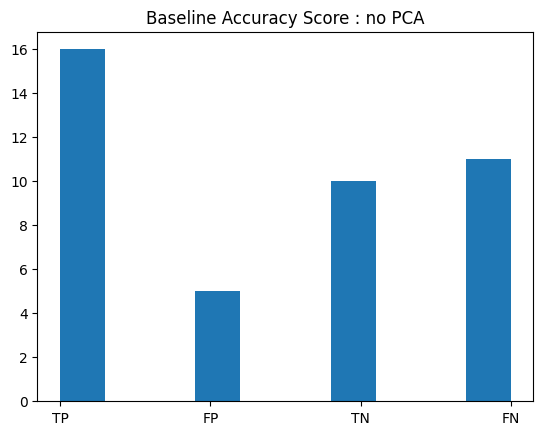

In [91]:
new_pipeline( model, X, y, "Baseline Accuracy Score : no PCA" )

# Task 2 : evaluate after PCA of 95% variance

In [92]:
from sklearn.decomposition import PCA

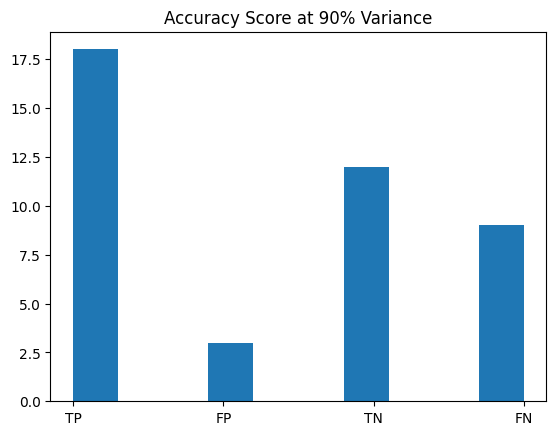

In [93]:
X_90 = PCA( n_components=0.9 ).fit_transform( X )
new_pipeline( model, X_90, y, "Accuracy Score at 90% Variance" )

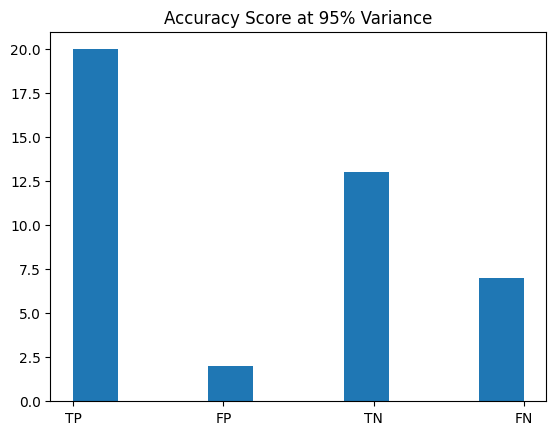

In [94]:
pca_95 = PCA( n_components=0.95 )
X_pca_95 = pca_95.fit_transform( X )
new_pipeline( model, X_pca_95, y,"Accuracy Score at 95% Variance" )

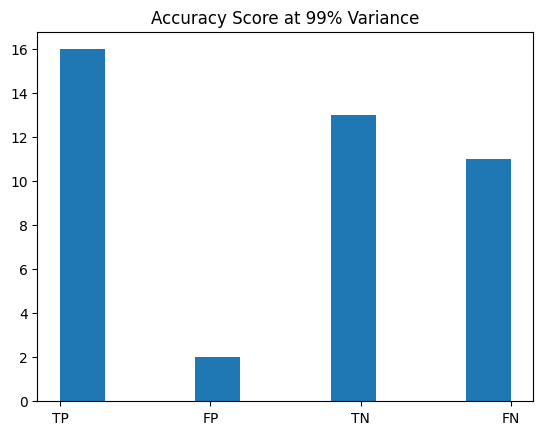

In [95]:
X_99 = PCA( n_components=0.99 ).fit_transform( X )
new_pipeline( model, X_99, y,"Accuracy Score at 99% Variance" )

# Task 3 : PCA with 2, 3, 10 components

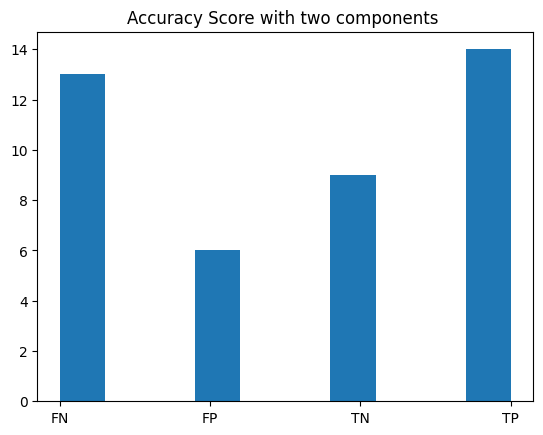

In [96]:
X_pca_two = PCA( n_components=2 ).fit_transform( X )

new_pipeline( model, X_pca_two, y, "Accuracy Score with two components " )

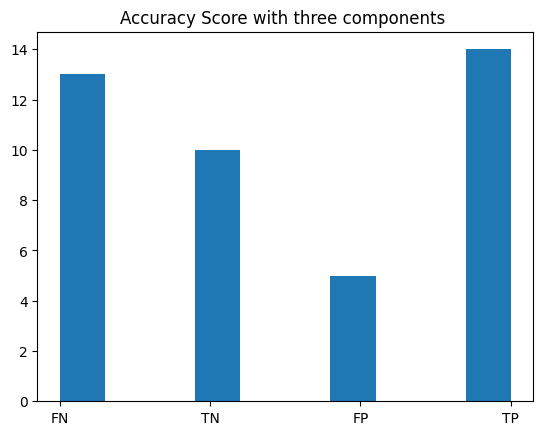

In [97]:
X_pca_three = PCA( n_components=3 ).fit_transform( X )

new_pipeline( model, X_pca_three, y, "Accuracy Score with three components " )

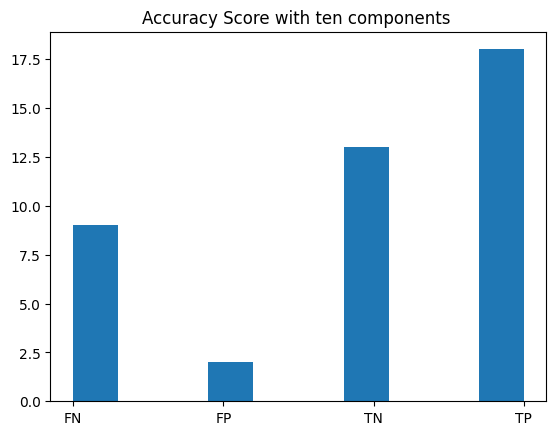

In [98]:
X_pca_ten = PCA( n_components=10 ).fit_transform( X )

new_pipeline( model, X_pca_ten, y, "Accuracy Score with ten components " )


Create a dataframe from dictionary for comparison

In [99]:
df = pd.DataFrame( model_dict )

In [100]:
df.head(len(df))

,model,TP,TN,FP,FN
0,Baseline Accuracy Score : no PCA,16,10,5,11
1,Accuracy Score at 90% Variance,18,12,3,9
2,Accuracy Score at 95% Variance,20,13,2,7
3,Accuracy Score at 99% Variance,16,13,2,11
4,Accuracy Score with two components,14,9,6,13
5,Accuracy Score with three components,14,10,5,13
6,Accuracy Score with ten components,18,13,2,9


# Plot the variance graphs ( explained, cumulative )

In [101]:
pca_full = PCA()
pca_full.fit_transform(X)

array([[ 9.70285283e-01, -1.01765376e+00, -8.30431877e-01, ...,
        -7.21377280e-03,  8.06511356e-03,  3.62503339e-03],
       [ 3.24435366e-01, -8.76876291e-01, -2.28203491e-01, ...,
        -5.14047549e-03, -3.31660809e-03, -3.23165044e-03],
       [-8.53571474e-01, -6.97734274e-01,  2.36015228e-02, ...,
        -2.40684236e-04,  9.49341531e-04,  2.23760439e-03],
       ...,
       [-3.06762512e-01,  1.14775550e+00, -2.48975461e-01, ...,
        -1.24237555e-04,  2.35831915e-03, -2.47607386e-03],
       [ 3.80831255e-02,  9.94048886e-01, -2.01938177e-01, ...,
         2.14739494e-03, -2.84903246e-04,  6.83064303e-04],
       [ 4.39041441e-02,  9.10802338e-01, -9.16916948e-03, ...,
        -4.95224124e-03, -7.78584807e-04,  1.34266891e-03]])

Explained Variance graph

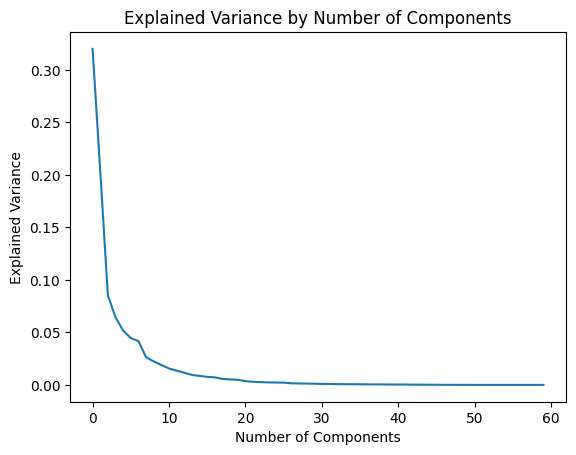

In [102]:

variance = pca_full.explained_variance_ratio_

plt.plot(variance)
plt.xlabel('Number of Components')
plt.ylabel('Explained Variance')
plt.title('Explained Variance by Number of Components')
plt.show()

Cumulative Explained Variance graph

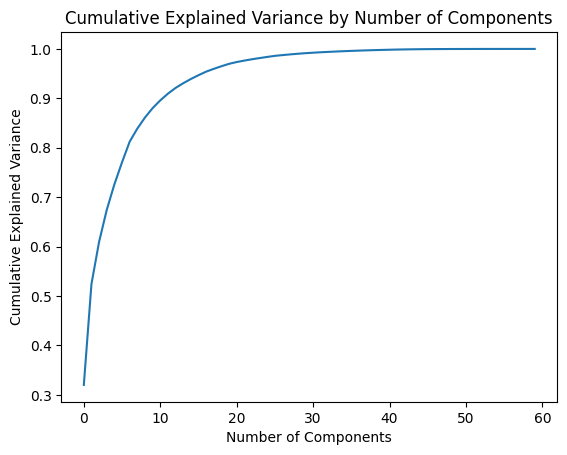

In [103]:
import numpy as np
cum_var = np.cumsum(variance)

plt.plot(cum_var)
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance by Number of Components')
plt.show()

In [104]:
var_dict = { "variance": variance, "cumulative_variance" : cum_var }
var_df = pd.DataFrame( var_dict )
var_df.head(len(var_df))

,variance,cumulative_variance
0,0.320037,0.320037
1,0.204339,0.524376
2,0.085490,0.609867
3,0.064459,0.674326
4,0.051683,0.726009
5,0.044629,0.770638
6,0.041713,0.812351
7,0.026413,0.838765
8,0.022385,0.861150
9,0.019022,0.880172
